## Домашнее задание № 1 (Макс. 10 баллов)

В данной домашней работе мы познакомимся на практике с пройденными темами, включающими в себя статистику, проверку гипотез и A/B тестирование.

### Задача 1 (2 балла)

**(1 Балл)** Рассчитайте среднее, стандартное отклонение и медиану по 1000 случайных выборок, порождённых нормальным распределением с $\mu = 5$ и $\sigma^2 = 4$, состоящих из 100 элементов. Постройте распределение полученных метрик.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as sps
from tqdm import tqdm

def calc_stat_random_sample(mu=5, sigma=4, size=100):
    ... # Место для вашего кода
    sample = sps.norm(loc=mu, scale=sigma ** 0.5).rvs(size=size)
    return(np.mean(sample), np.std(sample), np.median(sample))

n_samples = 1000

... # Место для вашего кода
mean_arr = []
std_arr = []
med_arr = []

for i in tqdm(range(1000)):
    m, s, med = calc_stat_random_sample()
    mean_arr.append(m)
    std_arr.append(s) 
    med_arr.append(med)

100%|██████████| 1000/1000 [00:00<00:00, 1481.74it/s]


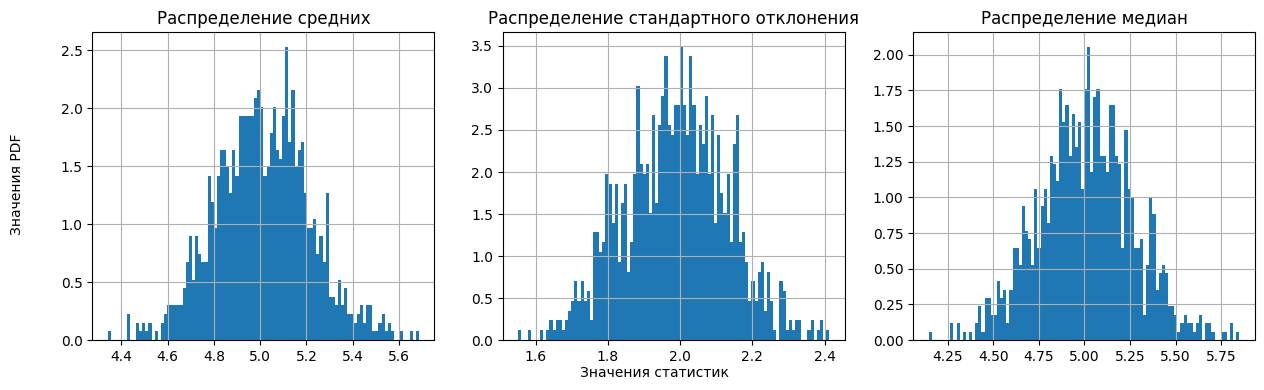

In [2]:
fig, axs = plt.subplots(1, 3, figsize = (15, 4))

axs[0].hist(mean_arr, bins = 100, density = True)
axs[1].hist(std_arr, bins = 100, density = True)
axs[2].hist(med_arr, bins = 100, density = True)


axs[0].set_title("Распределение средних")
axs[1].set_title("Распределение стандартного отклонения")
axs[2].set_title('Распределение медиан')

for ax in axs:
    ax.grid()

fig.supxlabel('Значения статистик', fontsize = 10)
fig.supylabel('Значения PDF', x = 0.07, fontsize = 10)
plt.show()

**(1 Балл)** Какому распределению принадлежит распределение средних? Почему?

Пусть у нас есть тысяча выборок вида $(X_1^{(i)}, \dots, X_{100}^{(i)}), \ i \in \{1, \dots, 1000\}$, $X_i^{(j)} \sim N(5, 4)$, причем они независимы.

Мы собираем с них статистику в виде среднего значения, то есть:
$$
S_i := \frac{1}{100}\sum_{j=1}^{100} X_j^{(i)}
$$
Теперь нам хотелось бы узнать распределение этих случайных величин, так как они независимы, то в бой вступают характеристические функции:
$$
\phi_{S_i}(t) = \phi_{\frac{1}{100} X_1^{(i)}}(t) \cdot \dots \cdot \phi_{\frac{1}{100} X_{100}^{(i)}}(t) =^{\text{iid}} 
$$
Мы знаем, что умножение на константу нормальной случайной величины оставляет её распределение, но меняет её параметры, то есть $\frac{1}{100} X_1^{(i)} \sim N(0.05, 0.0004)$
$$
=^{\text{iid}} (e^{0.05it - 0.0002t^2})^{100} = e^{5it - 0.02t^2}
$$
А тогда, раз её характеристическая функция имеет такой вид, то $S_i \sim N(5, 0.04)$. Это теоретическое обоснование подтверждает и график, так как наибольшее количество измерений сконцентрировано около 5, а стандартное отклонение действительно составляет $\sqrt{0.04}= 0.2$, так как почти все измерения укладываются в отрезок $[4.4, 5.6]$

### Задача 2 (2 балла):

Оцените значение $\hat{\mu}$ параметра $\mu$ **(1 балл)** для нормального распределения $\mathscr{N}(\mu,1)$ используя метод максимального правдоподобия.

Справка: функция плотности распределения для нормального распределения имеет вид:
$$
    f(x) = \frac{1}{\sqrt{2 \pi \sigma^2}} \text{e}^{-\frac{(x - \mu)^2}{2 \sigma^2}}
$$

Пусть у нас есть выборка $(X_1, \dots, X_n), \ X_i \sim N(\mu, 1)$.

Функция правдоподобия:
$$
L(\mu) = \prod_{i=1}^n f_{\mu}(X_i) =  \prod_{i=1}^n \frac{1}{\sqrt{2 \pi \sigma^2}} \text{e}^{-\frac{(X_i - \mu)^2}{2 \sigma^2}} = (\frac{1}{2 \pi \sigma^2})^{n/2} e^{-\frac{1}{2\sigma^2} \sum_{i=1}^n (X_i - \mu)^2}
$$

Её логарифм: 
$$
\ln {L(\mu)} = \frac{n}{2} \ln{\frac{1}{2 \pi \sigma^2}} - \frac{1}{2\sigma^2} \sum_{i=1}^n (X_i - \mu)^2 = -\frac{n}{2} \ln{(2 \pi \sigma^2)} - \frac{1}{2\sigma^2} \sum_{i=1}^n (X_i - \mu)^2
$$
Так как мы знаем, что $\sigma^2 = 1$, то получим:
$$
\ln {L(\mu)} = -\frac{n}{2} \ln{(2 \pi)} - \frac{1}{2} \sum_{i=1}^n (X_i - \mu)^2
$$
Дифференцируем: 
$$
\frac{\partial \ln {L(\mu)} }{\partial \mu} = \sum_{i=1}^n (X_i - \mu)
$$
Ищем экстремум: 
$$
\frac{\partial \ln {L(\mu)} }{\partial \mu} = \sum_{i=1}^n (X_i - \mu) = 0 \Rightarrow \sum_{i=1}^n X_i - n\mu = 0 \Rightarrow n\mu = \sum_{i=1}^n X_i
$$
Откуда:
$$
\hat \mu = \frac{1}{n} \sum_{i=1}^n X_i
$$
Для строгости было бы неплохо ещё показать, что найденное $\hat \mu  = \argmax_{\mu \in \mathbb{R}} L(\mu) = \argmax_{\mu \in \mathbb{R}} \ln {L(\mu)}$, так как логарифм - строго возрастающая функция. Для этого найдём вторую производную:
$$
\frac{\partial^2 \ln {L(\mu)} }{\partial \mu ^2} = -n <0
$$
Так как вторая производная строго меньше нуля, то функция выпукла вверх $\Rightarrow$ найденная точка - действительно максимум.

Сгенерируйте 1000 выборок размером 1000 наблюдений из нормального распределения с $\mu = 5, \sigma^2 = 1$, постройте распределение разности $\mu - \hat{\mu}$ и найдите среднее этой разности в зависимости от числа выборок **(1 балл)**.

In [37]:
# Место для вашего кода и картинок
sample_arr = []
mu = 5

for i in tqdm(range(1000)):
    sample_arr.append(sps.norm(loc = mu, scale = 1).rvs(size = 1000))

sample_arr = np.array(sample_arr)

100%|██████████| 1000/1000 [00:00<00:00, 1550.32it/s]


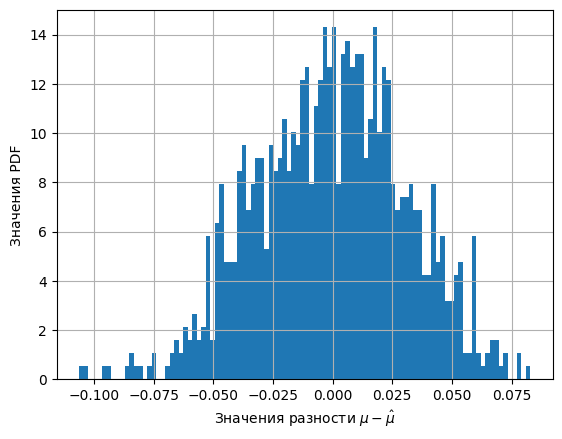

In [38]:
sample_arr = mu - sample_arr.mean(axis=1) 

plt.hist(sample_arr, bins = 100, density=True)
plt.ylabel("Значения PDF")
plt.xlabel("Значения разности $\mu - \hat \mu$")
plt.grid()
plt.show()
plt.show()

100%|██████████| 1000/1000 [00:00<00:00, 142964.89it/s]


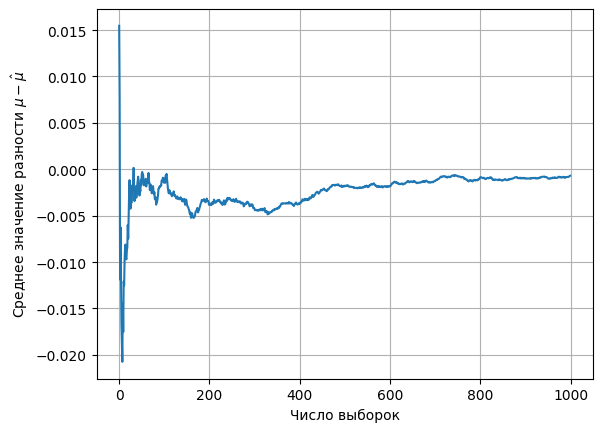

In [40]:
mps_arr = []
for i in tqdm(range(1, len(sample_arr) + 1)):
    mps_arr.append(sample_arr[:i].mean())


plt.plot(mps_arr)
plt.ylabel("Среднее значение разности $\mu - \hat \mu$")
plt.xlabel('Число выборок')
plt.grid()
plt.show()

### Задача 3 (2 балла)

**(1 балл)** Пусть известно, что выборка в n наблюдений порождена распределением Бернулли ~Bernoulli(p), пусть среднее значение по выборке равно $\hat{p}$. Постройте формулу 95% доверительного интервал для среднего

Пусть у нас есть выборка $(X_1, \dots, X_n), \ X_i \sim Bern(p)$. $\hat p := \frac{1}{n} \sum_{i=1}^n X_i$. Мы хотим подобрать $a, b \in \mathbb{R}$ такие, что:
$$
P_{\mathbb{E} X_i} ([a, b]) = P_{p} ([a, b]) = 0.95
$$
То есть мы строим оценку для параметра $p$.
Заметим, что для последовательности $\frac{1}{n}X_1, \frac{1}{n}X_2, \dots$ выполнена ЦПТ, так как это независимые одинаково распределенные случайные величины с конечной дисперсией, так как $\frac{1}{n}X_i \sim \begin{cases} \frac{1}{n}; \ p \\ 0; \ 1 - p\end{cases}$. А тогда мы знаем, что:
$$
\frac{\hat p - \mathbb{E} \hat p}{\sqrt{\mathbb{D} \hat p}} = \frac{\sqrt{n} (\hat p - p)}{\sqrt{p(1-p)}} \rightrightarrows^d_{n \to \infty} N(0, 1)
$$
Кроме того, мы знаем, что при поиске нужного интервала для нормального распределения нам достаточно рассматривать отрезки вида $[-b, b]$ в силу особенностей этого распределения, а тогда:
$$
P_{N(0, 1)} ([-b, b]) = \int_{-b}^b \frac{1}{\sqrt{2 \pi}} e^{-\frac{x^2}{2}} dx = \Phi(b) - \Phi(-b) = 0.95
$$
Тогда:
$$
\Phi(b) - 1 + \Phi(b) = 0.95 \Rightarrow 2\Phi(b) = 1.95 \Rightarrow \Phi(b) = 0.975
$$
Успех в том, что по таблице значений фишки можно явно подобрать $b = 1.96$. То есть:
$$
P(-1.96 \le \frac{\sqrt{n} (\hat p - p)}{\sqrt{p(1-p)}} \le 1.96) \rightrightarrows_{n \to \infty} 0.95
$$
Здесь же нам пригодится утверждение о том, что сходимость равномерная, так как строго говоря теперь мы можем делать границы интервала зависимыми от $n$:
$$
P(-1.96\frac{1}{\sqrt n} \le \frac{\hat p - p}{\sqrt{p(1-p)}} \le 1.96\frac{1}{\sqrt n}) = P(-1.96\frac{\sqrt{p(1-p)}}{\sqrt n} - \hat p \le -p \le 1.96\frac{\sqrt{p(1-p)}}{\sqrt n} - \hat p) = 
$$
$$
= P(-1.96\frac{\sqrt{p(1-p)}}{\sqrt n} + \hat p \le p \le 1.96\frac{\sqrt{p(1-p)}}{\sqrt n} + \hat p) \rightrightarrows_{n \to \infty} 0.95
$$
Однако здесь проблема, что границы интервала зависят от нашего параметра $p$, который мы здесь как раз и пытались оценить, поэтому вместо реального параметра напишем его оценку:
$$
P(-1.96\frac{\sqrt{\hat p(1-\hat p)}}{\sqrt n} + \hat p \le p \le 1.96\frac{\sqrt{\hat p(1- \hat p)}}{\sqrt n} + \hat p) \approx 0.95
$$
Тогда искомый интервал: $[-1.96\frac{\sqrt{\hat p(1-\hat p)}}{\sqrt n} + \hat p, 1.96\frac{\sqrt{\hat p(1- \hat p)}}{\sqrt n} + \hat p]$

**(1 балл)** Постройте 95% доверительный интервал на среднее в представленной выборке, используя бутстрап и сравните с теоретическим значением

In [ ]:
X = sps.bernoulli.rvs(0.2, size = 10000, random_state=42)

...

Ellipsis

### Задача 4 (4 балла)

Основным критерием для тестирования гипотезы о равенстве средних является t-test. Он строится на том, что по ЦПТ практически для любой случайной величины средние будут распределены нормально. 

В учебниках по статистике доказывается, что в силу этого для двух выборок, порождённых одинаково распределёнными независимыми случайными величинами с равным средним мы имеем асимпототику для выборочной t-статистики
$$
    T = \frac{\bar{x} - \bar{y}}{\sqrt{\frac{s_x^2}{n_1} + \frac{s_y^2}{n_2}}} \rightarrow t_{n_1 + n_2 - 2},
$$
где $\bar{x}, \bar{y}$ -- выборочные средние в выборках, $s_x^2, s_y^2$ -- выборочные дисперсии, $n_1, n_2$ -- размеры выборок, а $t_{n_1 + n_2 - 2}$ -- распределение Стьюдента с $n_1 + n_2 - 2$ степенями свободы.

**(1 балл)** Постройте плотность распределения Стьюдента с 1, 5, 10, 100 и 1000 степеней свободы, а также плотность стандартного нормального распределения

In [ ]:
grid = np.arange(-10,10,0.01)

freedom_degrees = [1,5,10,100,1000]

# Место для вашего кода и картинок

**(1 балл)** Пусть нам необходимо запустить A/B тест: в первой группе мы оставляем кнопку в банковском приложении в сером цвете, во втором -- красим её в жёлтый. Всего у нас в месяц в приложение заходит 1000 различных клиентов. Базовая конверсия в нажатие кнопки сейчас составляет 0.2. Бизнес постановил, что MDE = 5%, то есть значимым будет считаться изменение, при котором конверсия будет больше 0.21 или меньше 0.19. Хватит ли нам данных, чтобы замерить эффект за один месяц при уровне значимости $\alpha = 0.05$, если мы планируем поделить выборку пополам на тест и контроль?

In [ ]:
# Место для вашего кода

**(1 балл)** Мы провели тест и получили следующие результаты:

In [ ]:
X_1, X_2 = sps.bernoulli.rvs(0.2, size = 1000, random_state=42), sps.bernoulli.rvs(0.21, size = 1000, random_state=42)

Можем ли мы утверждать на уровне значимости $\alpha = 0.05$, что эффект имел место быть?

In [ ]:
# Место для вашего кода

**(1 балл)** 

Что будет, если мы проведём 1000 таких тестов, "отпустив" random_state?

В какой доле случаев мы не задетектируем это существующее различие? Чему будет равна $\beta$?

In [ ]:
# Под "отпущенным" random_state понимается None
# X_1, X_2 = sps.bernoulli.rvs(0.2, size = 1000), sps.bernoulli.rvs(0.21, size = 1000)

# Место для кода

А если различий не будет (при проведении 1000 A/A-тестов)? Как будет распределено p-value в этом случае?

In [ ]:
# Под A/A тестом имеем в виду: X_1, X_2 = sps.bernoulli.rvs(0.2, size = 1000), sps.bernoulli.rvs(0.2, size = 1000)

# Место для кода